# **RFM**-сегментация топ-клубов по трансферной активности

**Автор**: Шустов Никита · **Инструменты**: Python, pandas, numpy, seaborn, matplotlib, SQL (DuckDB)

## 1. Обзор проекта

RFM (Recency — давность, Frequency — частота, Monetary — сумма) — классический метод сегментации клиентов из маркетинга. В данном проекте он адаптирован для **футбольного рынка трансферов**: каждый клуб из топ-5 лиг рассматривается как «покупатель» трансферного рынка, а клубы группируются по тому, как давно, как часто и на какую сумму они покупают игроков.

**Бизнес-вопросы**

1. Какие клубы являются элитными покупателями на рынке и насколько сконцентрированы эти расходы?
2. Какие закономерности на рынке очевидны, а какие неожиданны?
3. Чем клубы-продавцы отличаются от клубов-покупателей?
4. Какие клубы выделяются необычными RFM-показателями («клубы-оригиналы»)?

**RFM-определения, использованные в проекте**

| Метрика | Маркетинговый смысл | Футбольная адаптация |
|---|---|---|
| **Recency** | Дней с последней покупки | Число сезонов между последним **крупным** трансфером клуба и последним сезоном в данных. Крупный — сделка из верхних 10% всех входящих трансферов своего сезона по сумме |
| **Frequency** | Количество заказов | Количество входящих трансферов (все типы: платные, свободные агенты, аренды) |
| **Monetary** | Общий доход | Общая сумма трансферных платежей за приобретённых игроков, млн евро (учитываются только сделки с указанной суммой) |

Дополнительно к трём классическим метрикам используются: **средний чек** (Monetary / Frequency) — для разделения клубов с дорогими точечными покупками и клубов с множеством недорогих сделок, и **Net Trade Ratio** — отдельный признак соотношения продаж и покупок (раздел 8).

**Метод:** очистка данных → таблица RFM → оценки от 1 до 5 → именованные сегменты (с учётом среднего чека) → визуальный анализ → стиль торговли (покупки и продажи) → выводы.

# 2. Настройка

In [1]:
!pip install -q --upgrade duckdb

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.6/21.6 MB 65.5 MB/s eta 0:00:00


# 3. Данные

Данные с сайта Transfermarkt. Для исследования используются сезоны 2015/16–2025/26 (сделки не позже 30.06.2026): в БД данные за лето 2026 года неполные.

**Используемые таблицы в БД**:
1. transfers — таблица трансферов
2. clubs — таблица с информацией по клубам

*Источник*: https://github.com/dcaribou/transfermarkt-datasets

**Пример из источника:**

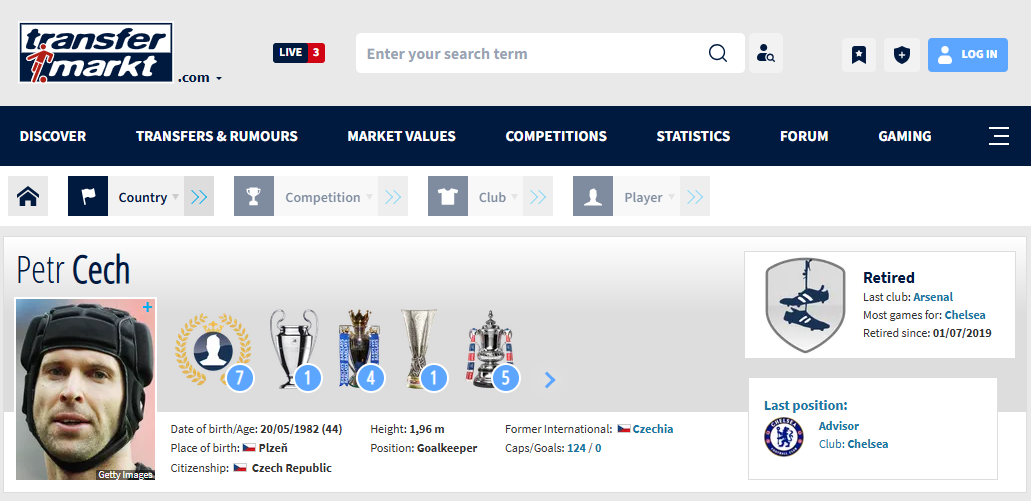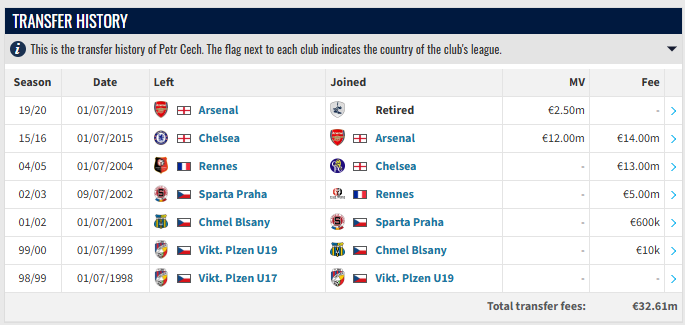

In [2]:
con = duckdb.connect(database='/content/transfermarkt-datasets.duckdb', read_only=True)

In [3]:
#таблицы в БД
tables = con.execute("SHOW TABLES;").fetchall()
print("Таблицы в базе данных:", tables)

Таблицы в базе данных: [('appearances',), ('club_games',), ('clubs',), ('competitions',), ('countries',), ('game_events',), ('game_lineups',), ('games',), ('national_teams',), ('player_valuations',), ('players',), ('transfers',), ('version',)]


In [4]:
#таблица по трансферам
raw = con.execute("SELECT * FROM transfers ;").df()
#общий обзор
audit = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(1),
    "unique": raw.nunique(),
})
display(audit)


,dtype,missing,missing_%,unique
player_id,int32,0,0.0,23379
transfer_date,datetime64[us],0,0.0,5634
transfer_season,object,0,0.0,35
from_club_id,int32,0,0.0,17408
to_club_id,int32,0,0.0,13208
from_club_name,object,0,0.0,18285
to_club_name,object,0,0.0,14086
transfer_fee,float64,61526,35.1,1503
market_value_in_eur,float64,68160,38.9,191
player_name,object,0,0.0,23036


### 3.1 Задвоение строк на возврате из аренды

В отличие от официального сайта, в БД сумма аренды = 0 (это один из признаков аренды в датасете). Возврат игрока из аренды записан отдельной строкой «в обратную сторону», тоже с суммой 0. Такая строка — не новая сделка: если её оставить, обе стороны получат лишнюю «покупку» или «продажу» и Frequency будет завышена.

Строка считается возвратом из аренды, если для того же игрока клубы «откуда» и «куда» зеркальны предыдущей сделке, сумма обеих сделок равна 0, а между датами не больше 730 дней. Это эвристика: сделки с пустой (NaN) суммой в проверку не попадают.

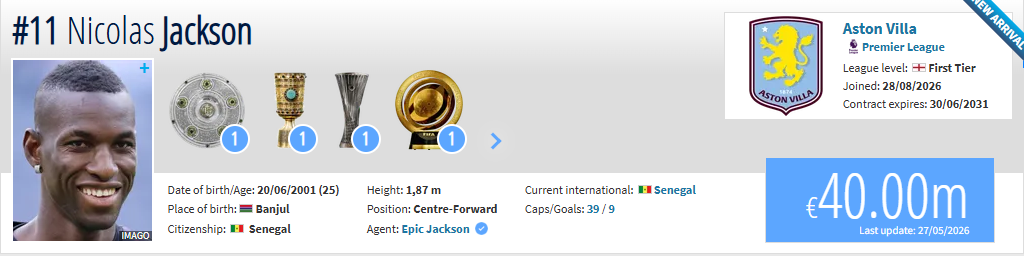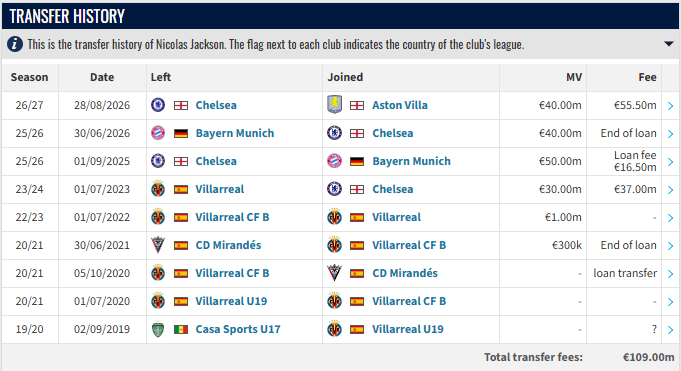

In [5]:
#новая таблица для проверки и столбцы prev
by_date = raw.sort_values(["player_id", "transfer_date"])
by_player = by_date.groupby("player_id", sort=False)
prev_from = by_player["from_club_id"].shift(1)
prev_to = by_player["to_club_id"].shift(1)
prev_fee = by_player["transfer_fee"].shift(1)
prev_date = by_player["transfer_date"].shift(1)
#проверка если True, это строка возврата из аренды
is_loan_return = (
    (by_date["from_club_id"] == prev_to)
    & (by_date["to_club_id"] == prev_from)
    & (by_date["transfer_fee"].eq(0))
    & (prev_fee.eq(0))
    & ((by_date["transfer_date"] - prev_date).dt.days <= 730)
).reindex(raw.index)


print(f"Найдено строк-возвратов из аренды: {is_loan_return.sum():,} из {len(raw):,} ({is_loan_return.mean():.1%})")
#is_loan_return еще используем в фильтрации данных

Найдено строк-возвратов из аренды: 31,450 из 175,165 (18.0%)


### 3.2 Добавляем флаги для определения аренд, свободных агентов и платных трансферов

In [6]:
# в таблице уход из клуба и завершение карьеры указаны строками в to_club_name;
# not_retired_or_free = True, если трансфер идёт в настоящий клуб (а не «Without Club» / «Retired»)
not_retired_or_free = ~raw['to_club_name'].isin(['Without Club', 'Retired'])

# free_agent_flag: 1, если transfer_fee пусто и переход в клуб, иначе 0
raw['free_agent_flag'] = np.where(raw['transfer_fee'].isna() & not_retired_or_free, 1, 0)

# loan_flag: 1, если transfer_fee ровно 0 и переход в клуб, иначе 0
raw['loan_flag'] = np.where(raw['transfer_fee'].eq(0) & not_retired_or_free, 1, 0)

raw['transfer_fee'] = raw['transfer_fee'].fillna(0)

# paid_flag: 1, если transfer_fee > 0 и переход в клуб, иначе 0
# (скобки обязательны: у & приоритет выше, чем у >, без них условие not_retired_or_free молча выпадает)
raw['paid_flag'] = np.where((raw['transfer_fee'] > 0) & not_retired_or_free, 1, 0)

# 4. Фильтрация данных

1. Убираем строки возврата из аренды (см. 3.1).
2. Берём сезоны 2015/16–2025/26 и сделки не позже 30.06.2026: данные за лето 2026 в БД неполные.
3. Убираем уход из клуба и завершение карьеры («Without Club», «Retired»).
4. Убираем переходы из молодёжных и резервных команд в основной состав — это внутренние перемещения, а не рынок. Ищем по названию клуба: суффиксы U18/U21/U23, «2», «B», «II» и т.п., например «Barcelona B», «Bayern Munich II».
5. Оставляем покупателей из топ-5 лиг (`GB1`, `ES1`, `IT1`, `L1`, `FR1` в таблице `clubs`). В выборку попадают и клубы, которые позже вылетели из этих лиг (например, Stoke City).

In [7]:
# единый список сезонов и дата отсечки: используются и здесь, и в воронке фильтров ниже
SEASONS = [f"{y % 100:02d}/{(y + 1) % 100:02d}" for y in range(2015, 2026)]   # '15/16' ... '25/26'
LAST_DATE = pd.Timestamp("2026-06-30")

seasons_mask = raw['transfer_season'].isin(SEASONS)
date_mask = raw['transfer_date'] <= LAST_DATE

# переходы ИЗ молодёжных/резервных команд; not_youth_from = True, если переход НЕ из такой команды (такие строки оставляем)
not_youth_from = ~raw['from_club_name'].str.contains(
    r"(?:U\d{2}|\s2|\sB|\sII|Youth|Primavera|Reserves|Juvenil)$", na=False, regex=True
)

# объединяем условия (not_retired_or_free задан в 3.2, is_loan_return — в 3.1)
final_mask = ~is_loan_return & seasons_mask & date_mask & not_retired_or_free & not_youth_from
df_temp = raw[final_mask]   # рынок за выбранный период: и покупки, и продажи (нужен и для расчёта продаж)

# смотрим покупателей только из топ-5 лиг
leagues = {"GB1": "Premier League", "ES1": "La Liga", "IT1": "Serie A", "L1": "Bundesliga", "FR1": "Ligue 1"}
top5_clubs = con.execute(
    "SELECT distinct club_id, domestic_competition_id FROM clubs WHERE domestic_competition_id IN ('GB1', 'FR1', 'L1', 'ES1', 'IT1') ;"
).df()
top5_clubs['club_id'] = top5_clubs['club_id'].astype(int)
top5_clubs["League"] = top5_clubs["domestic_competition_id"].map(leagues)

# объединение с фильтрованной частью
df_filtered = df_temp.merge(
    top5_clubs,
    left_on='to_club_id',
    right_on='club_id',
    how='inner'
)

df_filtered

,player_id,transfer_date,transfer_season,from_club_id,to_club_id,from_club_name,to_club_name,transfer_fee,market_value_in_eur,player_name,free_agent_flag,loan_flag,paid_flag,club_id,domestic_competition_id,League
0,195778,2026-06-30,25/26,79,27,Stuttgart,Bayern Munich,0.0,12000000.0,Alexander Nübel,0,1,0,27,L1,Bundesliga
1,338285,2026-06-30,25/26,1049,940,Valencia,Celta de Vigo,0.0,3500000.0,Unai Núñez,0,1,0,940,ES1,La Liga
2,543771,2026-06-30,25/26,114,46,Besiktas,Inter,0.0,12000000.0,Kristjan Asllani,0,1,0,46,IT1,Serie A
3,581672,2026-06-30,25/26,4172,405,Pisa,Aston Villa,0.0,6500000.0,Samuel Iling-Junior,0,1,0,405,GB1,Premier League
4,866247,2026-06-30,25/26,4159,430,Carrarese,Fiorentina,0.0,1200000.0,Tommaso Rubino,0,1,0,430,IT1,Serie A
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11801,333241,2015-07-01,15/16,8718,533,Sport Recife,Hoffenheim,2200000.0,1250000.0,Joelinton,0,0,1,533,L1,Bundesliga
11802,352332,2015-07-01,15/16,21688,1162,Concarneau,SM Caen,0.0,NaN,Florian Le Joncour,0,1,0,1162,FR1,Ligue 1
11803,355501,2015-07-01,15/16,10155,1025,San Marino,Bologna,600000.0,400000.0,Amadou Diawara,0,0,1,1025,IT1,Serie A
11804,357885,2015-07-01,15/16,5649,1084,Atl. Malagueño,Málaga CF,0.0,NaN,Pablo Fornals,1,0,0,1084,ES1,La Liga


### 4.1 Воронка фильтрации

Сколько строк отсеивает каждый шаг. Условия воронки — те же маски, по которым реально строится `df_temp`.

In [8]:
steps = []
mask = pd.Series(True, index=raw.index)

# функция для просмотра отсеивания данных: накапливаем условия и считаем, сколько строк осталось
def apply(name, cond):
    global mask
    mask &= cond
    steps.append((name, int(mask.sum())))

# добавляем все трансферы и применяем те же маски, что и в df_temp
steps.append(("Все трансферы в таблице", len(raw)))
apply("Без строк-возврата из аренды", ~is_loan_return)
apply("Сезоны 2015/16 – 2025/26", seasons_mask)
apply("Дата сделки не позже 30.06.2026", date_mask)
apply("Без Without Club / Retired", not_retired_or_free)
apply("Без переходов из U18/U21/B-команд", not_youth_from)

# проверка: воронка совпадает с реально применённым фильтром
assert int(mask.sum()) == len(df_temp), "Воронка не совпадает с df_temp"

# добавляем данные по покупателям из топ-5
steps.append(("Покупатель — клуб топ-5 лиг", len(df_filtered)))

# строим датафрейм
attrition = pd.DataFrame(steps, columns=["Шаг", "Строк осталось"])
attrition["Отсеяно, %"] = (1 - attrition["Строк осталось"] / attrition["Строк осталось"].shift(1)).mul(100)
attrition

,Шаг,Строк осталось,"Отсеяно, %"
0,Все трансферы в таблице,175165,NaN
1,Без строк-возврата из аренды,143715,17.954500
2,Сезоны 2015/16 – 2025/26,117980,17.906969
3,Дата сделки не позже 30.06.2026,117966,0.011866
4,Без Without Club / Retired,114913,2.588034
5,Без переходов из U18/U21/B-команд,79689,30.652755
6,Покупатель — клуб топ-5 лиг,11806,85.184906


### 4.2 Объём рынка по сезонам

Суммы номинальные (без поправки на инфляцию рынка), поэтому недавние сезоны заметно «дороже». Это важно для интерпретации Monetary: клубы, активные в последние годы, естественно окажутся выше.

,Всего_трансферов,Платных,Потрачено_млн
transfer_season,,,
15/16,625,297,2274.8080
16/17,717,363,3073.6735
17/18,782,404,4493.2560
18/19,920,439,4405.7500
19/20,1070,514,6052.5970
20/21,924,361,3548.9670
21/22,1123,444,3823.7490
22/23,1408,626,5988.5320
23/24,1438,648,6734.9550


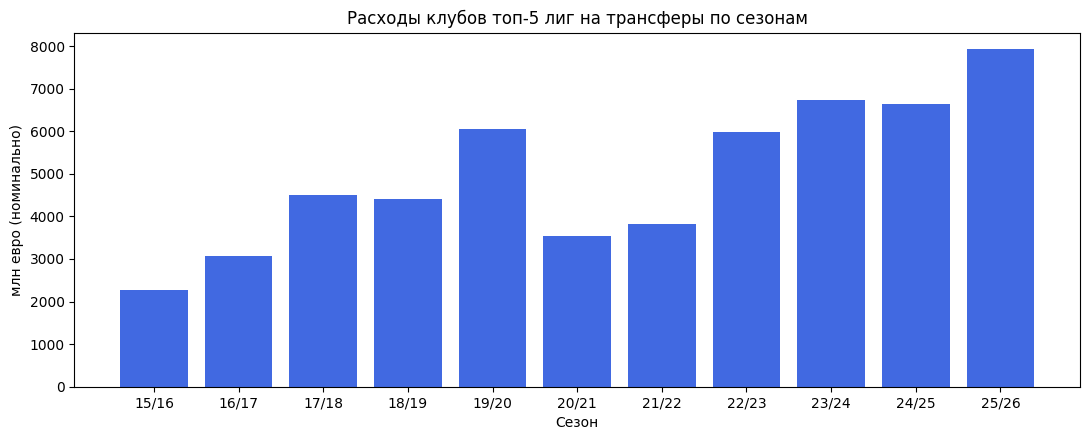

In [9]:
# датафрейм с расходами на трансферы по сезонам
df = df_filtered.copy()
df["fee_m"] = df["transfer_fee"] / 1_000_000

market = (
    df.groupby("transfer_season")
    .agg(Всего_трансферов=("player_id", "size"), Платных=("paid_flag", "sum"), Потрачено_млн=("fee_m", "sum"))
)
display(market)

# график расходов по сезонам
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(market.index, market["Потрачено_млн"], color="royalblue")
ax.set_title("Расходы клубов топ-5 лиг на трансферы по сезонам")
ax.set_xlabel("Сезон")
ax.set_ylabel("млн евро (номинально)")
plt.tight_layout()
plt.show()

# 5. RFM-показатели

1. **Recency** считаем только по крупным трансферам: сумма сделки входит в верхние 10% всех входящих трансферов своего сезона (порог — 90-й перцентиль; нулевые сделки тоже участвуют в распределении). Сравнение внутри сезона снимает влияние роста цен на рынке.
2. **Frequency** — все входящие сделки.
3. **Monetary** — общая сумма трансферных платежей.

In [10]:
# Порог 90-го перцентиля считаем для каждого сезона и сопоставляем с каждой строкой.
# Крупная сделка: сумма не меньше порога своего сезона и больше 0
df['season_threshold'] = df.groupby('transfer_season')['transfer_fee'].transform(lambda x: x.quantile(0.90))
df["is_big_deal"] = (df["transfer_fee"] >= df["season_threshold"]) & (df["transfer_fee"] > 0)

In [11]:
#порог для каждого года
thresholds = (df.groupby("transfer_season")["season_threshold"].first() / 1_000_000).rename("Порог крупной сделки, млн евро")

display(thresholds.to_frame())

,"Порог крупной сделки, млн евро"
transfer_season,
15/16,11.000
16/17,13.200
17/18,17.000
18/19,14.910
19/20,18.000
20/21,12.670
21/22,11.000
22/23,12.465
23/24,14.000


In [12]:
# справочные данные по клубам: самое частое название и лига, а также год начала сезона
club_names = df.groupby("club_id")["to_club_name"].agg(lambda s: s.mode().iat[0])
club_league = top5_clubs.drop_duplicates("club_id").set_index("club_id")["League"]
df["season_start"] = 2000 + df["transfer_season"].str[:2].astype(int)

# последний сезон, количество сезонов, границы Recency
SNAPSHOT_SEASON = df["season_start"].max()    # 2025 -> сезон 2025/26
WINDOW_LEN = int(df["transfer_season"].nunique())
R_BINS = [-1, 1, 4, 7, 10, np.inf]     # Recency: 0-1 / 2-4 / 5-7 / 8-10 / 11 (крупных сделок нет вовсе)

# функция для вычисления RFM
def compute_rfm(transfers, snapshot_season, window_len, r_bins):
    """Клубная таблица RFM: сырые значения, оценки 1-5, комбинированный FM."""
    rfm = transfers.groupby("club_id").agg(Frequency=("player_id", "size"), Monetary=("fee_m", "sum"))

    # клуб без крупных сделок получает Recency = длина окна (11) -> оценка R = 1
    last_big = transfers[transfers["is_big_deal"]].groupby("club_id")["season_start"].max()
    rfm["Recency"] = (snapshot_season - last_big.reindex(rfm.index)).fillna(window_len).astype(int)

    # Recency — фиксированные интервалы (много клубов с одинаковыми значениями, квантили не подходят)
    rfm["R"] = pd.cut(rfm["Recency"], bins=r_bins, labels=[5, 4, 3, 2, 1]).astype(int)
    # Frequency и Monetary — квинтили; rank(method='first') разрывает ничьи
    rfm["F"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
    rfm["M"] = pd.qcut(rfm["Monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

    rfm["FM"] = np.floor((rfm["F"] + rfm["M"]) / 2 + 0.5).astype(int)     # среднее F и M, .5 округляется вверх
    rfm["RFM_Score"] = rfm["R"].astype(str) + rfm["F"].astype(str) + rfm["M"].astype(str)
    rfm.insert(0, "Club", club_names.reindex(rfm.index).values)
    rfm.insert(1, "League", club_league.reindex(rfm.index).values)
    assert rfm["Club"].is_unique, "Есть клубы с одинаковыми названиями"
    return rfm


rfm = compute_rfm(df, SNAPSHOT_SEASON, WINDOW_LEN, R_BINS).set_index("Club")
rfm.sort_values("Monetary", ascending=False).head(10)

,League,Frequency,Monetary,Recency,R,F,M,FM,RFM_Score
Club,,,,,,,,,
Chelsea,Premier League,84,2697.40,0,5,4,5,5,545
Man City,Premier League,76,2215.83,0,5,4,5,5,545
Man Utd,Premier League,53,2004.07,0,5,2,5,4,525
PSG,Ligue 1,68,1833.72,0,5,3,5,4,535
Juventus,Serie A,103,1542.30,0,5,5,5,5,555
Arsenal,Premier League,61,1530.70,0,5,2,5,4,525
Liverpool,Premier League,46,1492.45,0,5,1,5,3,515
Tottenham,Premier League,72,1436.05,0,5,3,5,4,535
Barcelona,La Liga,70,1353.09,0,5,3,5,4,535


**Логика оценок**

| Оценка | Recency (сезонов с последней крупной сделки) | Frequency / Monetary |
|---|---|---|
| 5 | 0–1 (крупная сделка в последних двух сезонах) | верхние 20% клубов |
| 4 | 2–4 | следующие 20% |
| 3 | 5–7 | средние 20% |
| 2 | 8–10 | следующие 20% |
| 1 | 11 (за все 11 сезонов крупных сделок нет вовсе) | нижние 20% |

`FM` — среднее оценок F и M, округлённое (.5 вверх). Оно нужно, чтобы карта сегментов оставалась читаемой: две оси (R и FM) вместо трёх. Frequency и Monetary заметно связаны (коэффициент Спирмена см. в 5.1), но не дублируют друг друга.

### 5.1 Распределения исходных значений


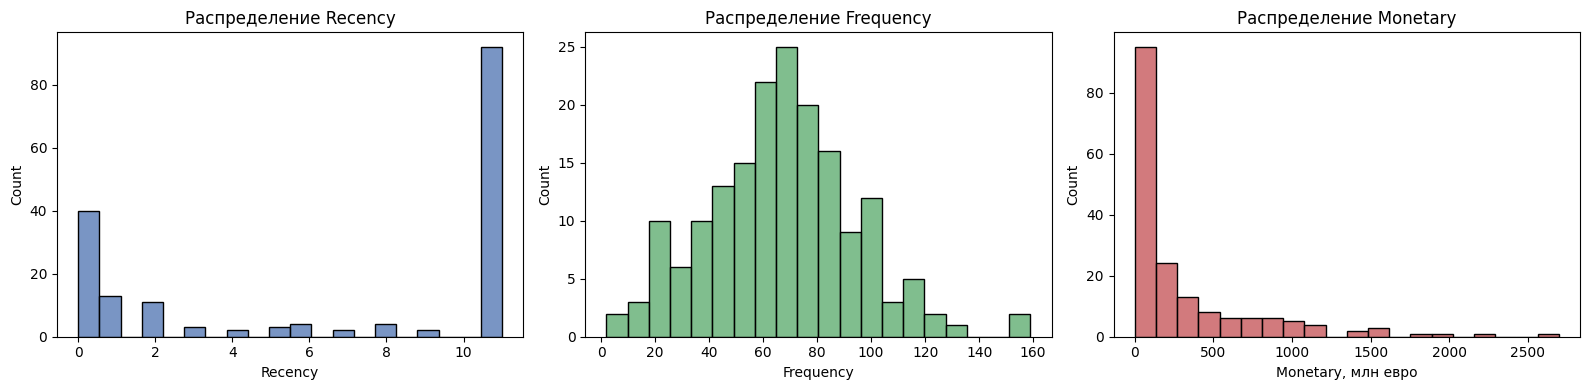

,count,mean,std,min,25%,50%,75%,max
Recency,176.0,6.630682,4.925151,0.0,1.0000,11.0000,11.0000,11.0
Frequency,176.0,67.079545,27.537703,2.0,49.7500,67.0000,84.0000,159.0
Monetary,176.0,312.218395,464.195597,0.0,24.5575,111.7525,397.2225,2697.4


Корреляция Спирмена между метриками:


,Recency,Frequency,Monetary
Recency,1.000000,-0.527195,-0.882571
Frequency,-0.527195,1.000000,0.676281
Monetary,-0.882571,0.676281,1.000000


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, color in zip(axes, ["Recency", "Frequency", "Monetary"], ["#4c72b0", "#55a868", "#c44e52"]):
    sns.histplot(rfm[col], bins=20, ax=ax, color=color)
    ax.set_title(f"Распределение {col}")
axes[2].set_xlabel("Monetary, млн евро")
plt.tight_layout()
plt.show()

display(rfm[["Recency", "Frequency", "Monetary"]].describe().T)
print("Корреляция Спирмена между метриками:")
display(rfm[["Recency", "Frequency", "Monetary"]].corr(method="spearman"))

**Комментарий к корреляциям.** Recency связана с Monetary сильнее (ρ Спирмена около −0,88), чем Frequency с Monetary (около 0,68). Это не содержательная связь, а в значительной мере механический эффект: Monetary и Frequency — суммы за всё окно наблюдения, а клуб, переставший делать крупные покупки несколько сезонов назад, не успел их накопить. Поэтому R и M в один показатель не объединяются: они отвечают на разные вопросы (когда клуб был активен и насколько он велик как покупатель). Также у более чем половины клубов Recency равна 11 (медиана = 11): крупных сделок не было вовсе.

# 6. Сегментация

Сегменты строятся по трём признакам: **R** (как давно клуб делал крупную покупку), **FM** (масштаб клуба как покупателя) и **средний чек** (Monetary / Frequency — среднее на одну входящую сделку любого типа; аренды и свободные агенты входят с нулевой суммой). Средний чек используется только внутри группы активных крупных покупателей (R ≥ 4 и FM ≥ 4): он отделяет «дорого и точечно» от «дёшево и много». Граница — медиана среднего чека этой группы.

R ≥ 4 означает, что крупная сделка была не позже 4 сезонов назад (Recency 0–4).

| Сегмент | Правило | Интерпретация |
|---|---|---|
| **Точечные транжиры** | R ≥ 4, FM ≥ 4, средний чек ≥ медианы группы | Недавние крупные сделки, высокий объём трат, дорогие игроки |
| **Активные оптовики** | R ≥ 4, FM ≥ 4, средний чек < медианы группы | Та же активность и объём, но за счёт множества недорогих сделок |
| **Активные точечные** | R ≥ 4, FM = 3 | Недавние крупные сделки, средний объём трат |
| **Редкие покупатели** | R = 3 (любой FM) **или** R ≥ 4 при FM ≤ 2 | Крупная сделка была 5–7 сезонов назад либо клуб активен, но тратит мало |
| **Притихшие покупатели** | R = 2 (любой FM) | Последняя крупная сделка 8–10 сезонов назад |
| **Малые траты** | R = 1 (любой FM) | За все 11 сезонов не было ни одной крупной сделки |

Сегмент «Малые траты» объединяет все клубы без крупных сделок независимо от FM; на текущих данных это более половины клубов.

In [14]:
# средний чек = Monetary / Frequency: среднее на одну входящую сделку любого типа (аренды и свободные агенты входят с нулевой суммой), млн евро
rfm["Avg_Check"] = rfm["Monetary"] / rfm["Frequency"]

SEGMENT_ORDER = [
    "Точечные транжиры", "Активные оптовики", "Активные точечные",
    "Редкие покупатели", "Притихшие покупатели", "Малые траты",
]

# порог "дорого/дёшево" считается только внутри группы активных крупных покупателей,
# а не по всему рынку — иначе на пороге сказывались бы и мелкие клубы, для которых он не важен
top_group = (rfm["R"] >= 4) & (rfm["FM"] >= 4)
avg_check_threshold = rfm.loc[top_group, "Avg_Check"].median()

def assign_segment(r: int, fm: int, avg_check: float) -> str:
    if r >= 4 and fm >= 4:
        return "Точечные транжиры" if avg_check >= avg_check_threshold else "Активные оптовики"
    if r >= 4 and fm == 3:
        return "Активные точечные"
    if r >= 3:                        # R = 3 (любой FM) и R >= 4 при FM <= 2
        return "Редкие покупатели"
    if r >= 2:                        # R = 2
        return "Притихшие покупатели"
    return "Малые траты"              # R = 1

rfm["Segment"] = [
    assign_segment(r, fm, ac) for r, fm, ac in zip(rfm["R"], rfm["FM"], rfm["Avg_Check"])
]
rfm["Segment"] = pd.Categorical(rfm["Segment"], categories=SEGMENT_ORDER, ordered=True)

print(f"Порог среднего чека внутри активных крупных покупателей: {avg_check_threshold:.1f} млн евро")

segment_summary = (
    rfm.groupby("Segment", observed=True)
    .agg(
        Клубов=("Recency", "size"),
        Ср_Recency=("Recency", "mean"),
        Ср_Frequency=("Frequency", "mean"),
        Ср_Monetary_млн=("Monetary", "mean"),
        Ср_Чек_млн=("Avg_Check", "mean"),
        Всего_Monetary_млн=("Monetary", "sum"),
    )
)
segment_summary["Доля_клубов_%"] = segment_summary["Клубов"] / segment_summary["Клубов"].sum() * 100
segment_summary["Доля_трат_%"] = segment_summary["Всего_Monetary_млн"] / segment_summary["Всего_Monetary_млн"].sum() * 100
segment_summary

Порог среднего чека внутри активных крупных покупателей: 6.3 млн евро


,Клубов,Ср_Recency,Ср_Frequency,Ср_Monetary_млн,Ср_Чек_млн,Всего_Monetary_млн,Доля_клубов_%,Доля_трат_%
Segment,,,,,,,,
Точечные транжиры,32,0.125000,79.125000,1098.468625,14.507156,35150.9960,18.181818,63.968546
Активные оптовики,31,1.258065,94.677419,365.551774,3.886547,11332.1050,17.613636,20.622411
Активные точечные,5,1.600000,54.400000,438.154400,9.141102,2190.7720,2.840909,3.986814
Редкие покупатели,10,5.400000,69.700000,190.418000,2.828473,1904.1800,5.681818,3.465268
Притихшие покупатели,6,8.333333,66.500000,112.569667,1.693860,675.4180,3.409091,1.229140
Малые траты,92,11.000000,54.032609,40.184418,0.628145,3696.9665,52.272727,6.727820


In [15]:
for seg in SEGMENT_ORDER:
    members = rfm[rfm["Segment"] == seg].sort_values("Monetary", ascending=False).index.tolist()
    if members:
        print(f"{seg} ({len(members)}): {', '.join(members)}\n")

Точечные транжиры (32): Chelsea, Man City, Man Utd, PSG, Juventus, Arsenal, Tottenham, Barcelona, Atlético, Newcastle, West Ham, AC Milan, Real Madrid, Leipzig, Bayern Munich, Napoli, Inter, Aston Villa, Wolves, Everton, Roma, Dortmund, Monaco, Brighton, Bournemouth, Leverkusen, Leicester, Stade Rennais, Southampton, Crystal Palace, Leeds, Brentford

Активные оптовики (31): Atalanta, Nott'm Forest, Marseille, Lyon, Sevilla FC, Fiorentina, Burnley, Wolfsburg, Villarreal, Fulham, Frankfurt, Lille, Bologna, Lazio, Sassuolo, Nice, Real Betis, Torino, Stuttgart, R. Strasbourg, Udinese, Hoffenheim, Sunderland, Genoa, Como, Lens, Sheff Utd, Celta de Vigo, Augsburg, Girona, Salernitana

Активные точечные (5): Liverpool, Real Sociedad, Ipswich, UD Almería, Norwich

Редкие покупатели (10): Valencia, Watford, Mönchengladbach, Cagliari, Hertha BSC, Sampdoria, Espanyol, West Brom, Athletic Club, 1.FC Nuremberg

Притихшие покупатели (6): FC Schalke 04, Stoke City, Middlesbrough, 1.FC Köln, Hamburg, 

### 6.1 Кто попадает в какие сегменты

**Элитный уровень — «Точечные транжиры»**
1. Топ-клубы топ-5 лиг: Arsenal, Tottenham, Barcelona, Atlético.
2. Средние клубы АПЛ — самой богатой лиги мира: Newcastle, West Ham.
3. Клубы-«кузницы талантов» с высокой оборачиваемостью состава: Dortmund, Brighton (насколько они «продавцы», показывает раздел 8).

**Активные клубы вне элитного сегмента — «Активные оптовики» и «Активные точечные»**
1. Средние клубы других лиг, «прыгающие выше головы» и попадающие в еврокубки, что приводит к дополнительному финансированию: Hoffenheim, Como («Активные оптовики»).
2. Клубы, только прорвавшиеся из второго дивизиона Англии, получают достаточно денег для активных покупок, но за счёт недорогих игроков: Burnley («Активные оптовики»).
3. Средние клубы с богатым владельцем и крупными трансферными экспериментами: UD Almería («Активные точечные»).

**Притихшие покупатели**
1. Бывшие участники топ-лиг, давно не делавшие крупных покупок: FC Schalke 04, 1.FC Köln, Hamburg.
2. Средние клубы АПЛ, вылетевшие из лиги: Stoke City, Swansea.
3. Middlesbrough: последняя крупная покупка приходится на 2015–2017 годы — период выхода клуба в АПЛ.

**Малые траты**
1. Средние и малые клубы топ-4 лиг вне АПЛ: Heidenheim, Parma.
2. Клубы-«лифты», попадающие в топ-лигу и сразу вылетающие: Luton.
3. Бывшие большие клубы в кризисе: G. Bordeaux.
4. Стабильные клубы Бундеслиги с экономной моделью: Mainz, Freiburg.

# 7. Визуальный анализ

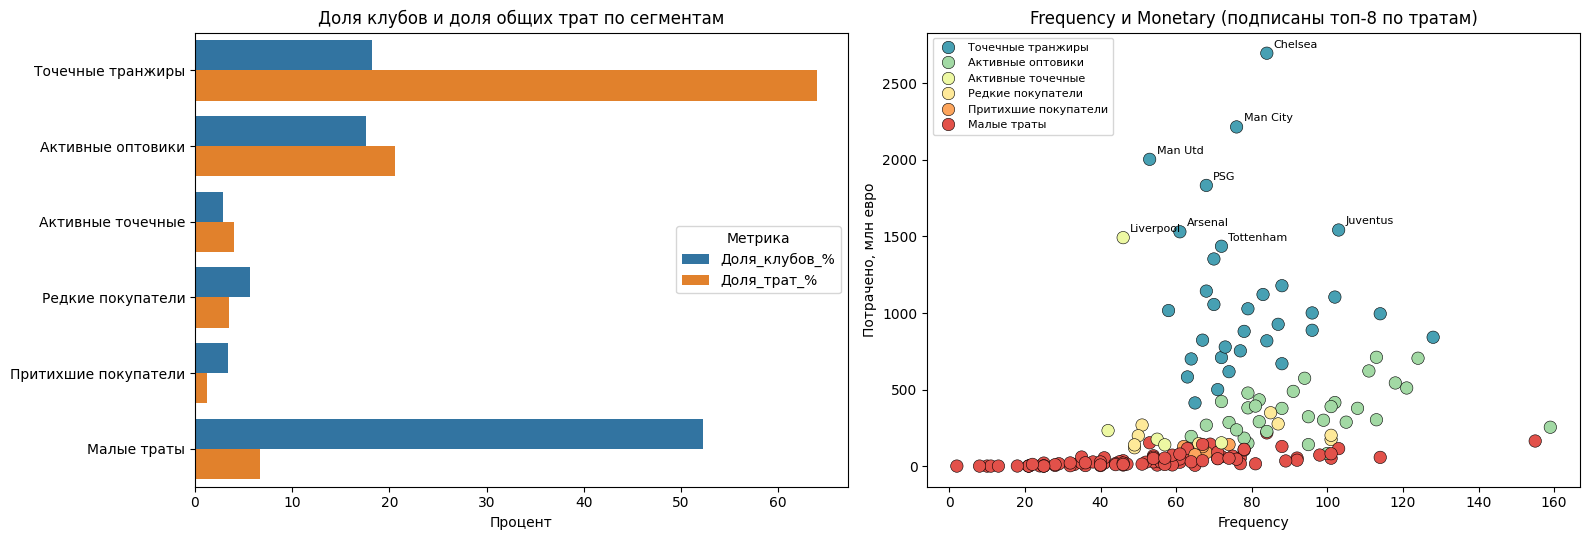

In [16]:
palette = dict(zip(SEGMENT_ORDER, sns.color_palette("Spectral_r", len(SEGMENT_ORDER))))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# доля клубов и доля трат по сегментам
share = segment_summary[["Доля_клубов_%", "Доля_трат_%"]].reset_index().melt(id_vars="Segment", var_name="Метрика", value_name="Процент")
sns.barplot(data=share, y="Segment", x="Процент", hue="Метрика", ax=axes[0])
axes[0].set_title("Доля клубов и доля общих трат по сегментам")
axes[0].set_ylabel("")

# Frequency vs Monetary
sns.scatterplot(data=rfm.reset_index(), x="Frequency", y="Monetary", hue="Segment", hue_order=SEGMENT_ORDER,
                palette=palette, s=80, edgecolor="black", linewidth=0.4, ax=axes[1])
for club, row in rfm.nlargest(8, "Monetary").iterrows():
    axes[1].annotate(club, (row["Frequency"], row["Monetary"]), xytext=(5, 4), textcoords="offset points", fontsize=8)
axes[1].set_title("Frequency и Monetary (подписаны топ-8 по тратам)")
axes[1].set_ylabel("Потрачено, млн евро")
axes[1].legend(fontsize=8, loc="upper left")

plt.tight_layout()
plt.show()

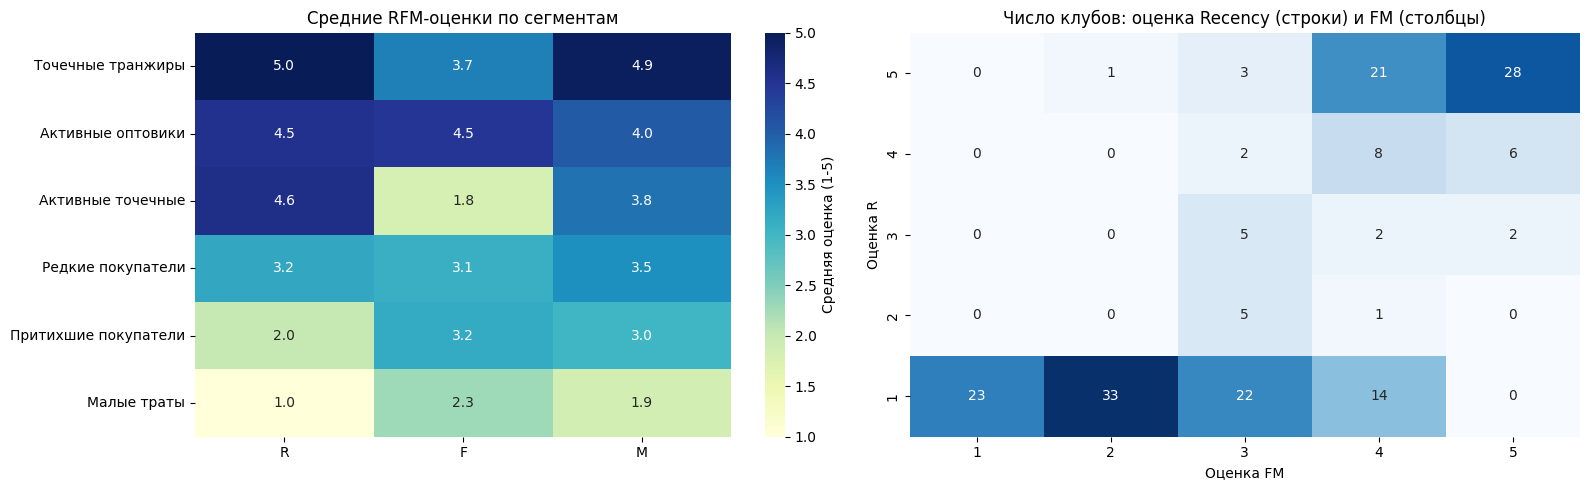

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# профиль сегментов: средние оценки R, F, M
profile = rfm.groupby("Segment", observed=True)[["R", "F", "M"]].mean()
sns.heatmap(profile, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={"label": "Средняя оценка (1-5)"}, ax=axes[0])
axes[0].set_title("Средние RFM-оценки по сегментам")
axes[0].set_ylabel("")

# число клубов по R и FM
grid = pd.crosstab(rfm["R"], rfm["FM"]).reindex(index=[5, 4, 3, 2, 1], columns=[1, 2, 3, 4, 5], fill_value=0)
sns.heatmap(grid, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1])
axes[1].set_title("Число клубов: оценка Recency (строки) и FM (столбцы)")
axes[1].set_xlabel("Оценка FM")
axes[1].set_ylabel("Оценка R")

plt.tight_layout()
plt.show()

### 7.1 Сегменты по лигам

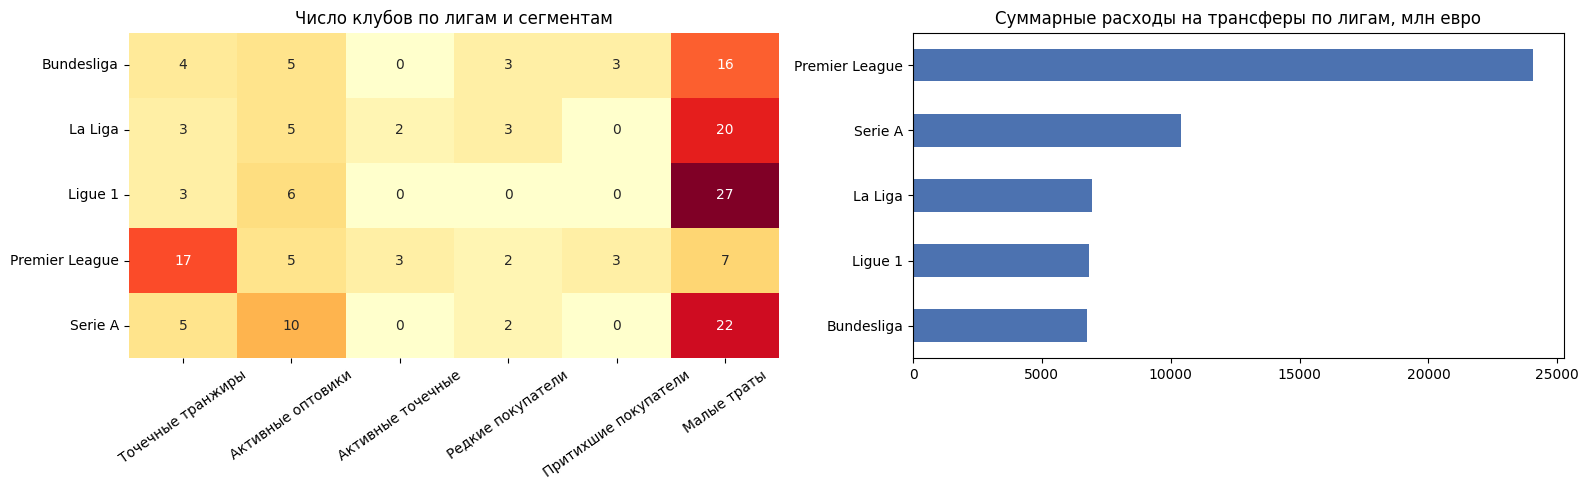

Segment,Точечные транжиры,Активные оптовики,Активные точечные,Редкие покупатели,Притихшие покупатели,Малые траты
League,,,,,,
Bundesliga,4,5,0,3,3,16
La Liga,3,5,2,3,0,20
Ligue 1,3,6,0,0,0,27
Premier League,17,5,3,2,3,7
Serie A,5,10,0,2,0,22


,Клубов,Всего_млн,Среднее_на_клуб_млн
League,,,
Premier League,37,24055.4180,650.146432
Serie A,39,10386.0335,266.308551
La Liga,33,6931.4050,210.042576
Ligue 1,36,6828.2580,189.673833
Bundesliga,31,6749.3230,217.720097


In [18]:
league_seg = pd.crosstab(rfm["League"], rfm["Segment"]).reindex(columns=SEGMENT_ORDER, fill_value=0)
league_spend = rfm.groupby("League")["Monetary"].agg(["count", "sum", "mean"]).rename(
    columns={"count": "Клубов", "sum": "Всего_млн", "mean": "Среднее_на_клуб_млн"})

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(league_seg, annot=True, fmt="d", cmap="YlOrRd", cbar=False, ax=axes[0])
axes[0].set_title("Число клубов по лигам и сегментам")
axes[0].set_xlabel("")
axes[0].set_ylabel("")
axes[0].tick_params(axis="x", rotation=35)

league_spend["Всего_млн"].sort_values().plot.barh(ax=axes[1], color="#4c72b0")
axes[1].set_title("Суммарные расходы на трансферы по лигам, млн евро")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

display(league_seg)
display(league_spend.sort_values("Всего_млн", ascending=False))

### 7.2 Неожиданное: Серия A

**Что видно в данных.** Серия A — вторая по расходам лига выборки после АПЛ: порядка 10 млрд евро за 11 сезонов против примерно 6,7–6,9 млрд у Ла Лиги, Лиги 1 и Бундеслиги; в среднем на клуб Серия A тоже вторая (см. таблицу выше). Часть разрыва по суммарным расходам объясняется числом клубов в выборке: из-за вылетов и повышений в Серии A их больше, чем в других лигах.

**Гипотезы (из общих представлений о рынке; проверяются таблицами ниже):**
- В Испании и Германии основные траты сосредоточены у двух-трёх клубов («Реал», «Барселона», «Атлетико»; «Бавария», «Боруссия Дортмунд», «РБ Лейпциг»), а остальные клубы лиги тратят скромнее. Проверка — доля трёх крупнейших клубов в расходах лиги.
- Клубы Серии A покупают игроков преимущественно друг у друга, и деньги циркулируют внутри лиги. Условный пример: «Ювентус» покупает игрока у «Фиорентины» за 60 млн, а «Фиорентина» тратит эти деньги на игроков из «Вероны» или «Дженоа» — средний чек растёт у всей лиги. Проверка — доля трат на игроков из клубов той же лиги.

**Фоновые факторы (внешние данные, не из датасета).**
- «Декрет о росте» (Decreto Crescita, 2019) снижал налоговую нагрузку на доходы специалистов, переезжающих в Италию: игрок платил подоходный налог с 50% дохода, и это удешевляло для клубов покупку игроков из-за рубежа. С 1 января 2024 года льгота для спортсменов отменена. Источники: [CBS Sports](https://www.cbssports.com/soccer/news/what-serie-a-giants-need-to-do-in-the-january-transfer-window-why-a-new-tax-law-might-change-teams-approach), [Calcio e Finanza](https://www.calcioefinanza.it/2023/12/29/quanto-risparmia-la-serie-a-con-il-decreto-crescita/).
- В Ла Лиге действует лимит затрат на состав (Límite de Coste de Plantilla Deportiva). Он ограничивает расходы клубов среднего звена; как именно это отражается на размере трансферных чеков — гипотеза, данными не проверяется.

In [19]:
# Проверка гипотез из 7.2

# 1) концентрация: доля трёх крупнейших клубов в расходах лиги
top3_share = (
    rfm.groupby("League")["Monetary"]
    .apply(lambda s: s.nlargest(3).sum() / s.sum())
    .mul(100).round(0)
    .rename("Доля топ-3 клубов в расходах лиги, %")
)
display(top3_share.sort_values(ascending=False).to_frame())

# 2) циркуляция денег: у клуба какой лиги куплены игроки (по лиге продавца)
seller_league = df["from_club_id"].map(club_league)      # NaN, если продавец не входит в клубы выборки
origin = np.select(
    [seller_league.isna(), seller_league.eq(df["League"])],
    ["продавец вне клубов выборки", "своя лига"],
    default="другая лига топ-5",
)
spend_by_origin = (
    df.assign(Источник=origin)
    .pivot_table(index="League", columns="Источник", values="fee_m", aggfunc="sum", fill_value=0)
)
spend_by_origin_pct = spend_by_origin.div(spend_by_origin.sum(axis=1), axis=0).mul(100).round(1)
print("Откуда куплены игроки (доля расходов лиги, %):")
display(spend_by_origin_pct)

,"Доля топ-3 клубов в расходах лиги, %"
League,
La Liga,52.0
Ligue 1,49.0
Bundesliga,42.0
Serie A,35.0
Premier League,29.0


Откуда куплены игроки (доля расходов лиги, %):


Источник,другая лига топ-5,продавец вне клубов выборки,своя лига
League,,,
Bundesliga,35.8,35.7,28.4
La Liga,42.0,30.4,27.6
Ligue 1,35.9,34.4,29.7
Premier League,40.9,23.9,35.3
Serie A,29.3,27.0,43.6


### 7.3 Траектории трат крупнейших покупателей

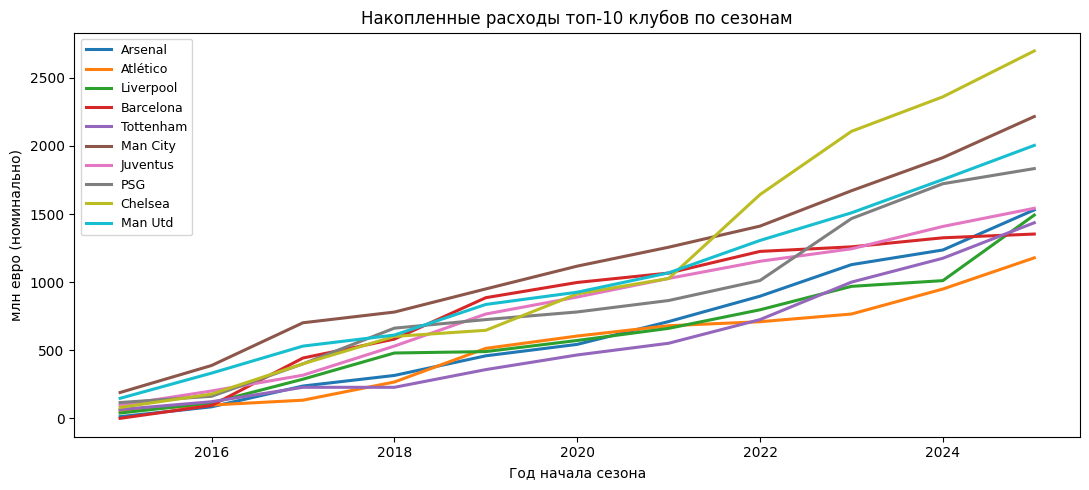

In [20]:
top_names = rfm.nlargest(10, "Monetary").index
top_ids = club_names[club_names.isin(top_names)].index

trajectory = (
    df[df["club_id"].isin(top_ids)]
    .pivot_table(index="season_start", columns="club_id", values="fee_m", aggfunc="sum")
    .reindex(range(2015, SNAPSHOT_SEASON + 1)).fillna(0).cumsum()
    .rename(columns=club_names)
)

fig, ax = plt.subplots(figsize=(11, 5))
trajectory.plot(ax=ax, linewidth=2.2)
ax.set_title("Накопленные расходы топ-10 клубов по сезонам")
ax.set_ylabel("млн евро (номинально)")
ax.set_xlabel("Год начала сезона")
ax.legend(title="", fontsize=9)
plt.tight_layout()
plt.show()

### 7.4 Чистые траты (net spend)

RFM смотрит только на покупки. Добавив продажи, можно отличить чистых покупателей от клубов, которые финансируют покупки продажей игроков. `Net_Spend = Потрачено − Заработано`; положительное значение — клуб потратил больше, чем заработал.

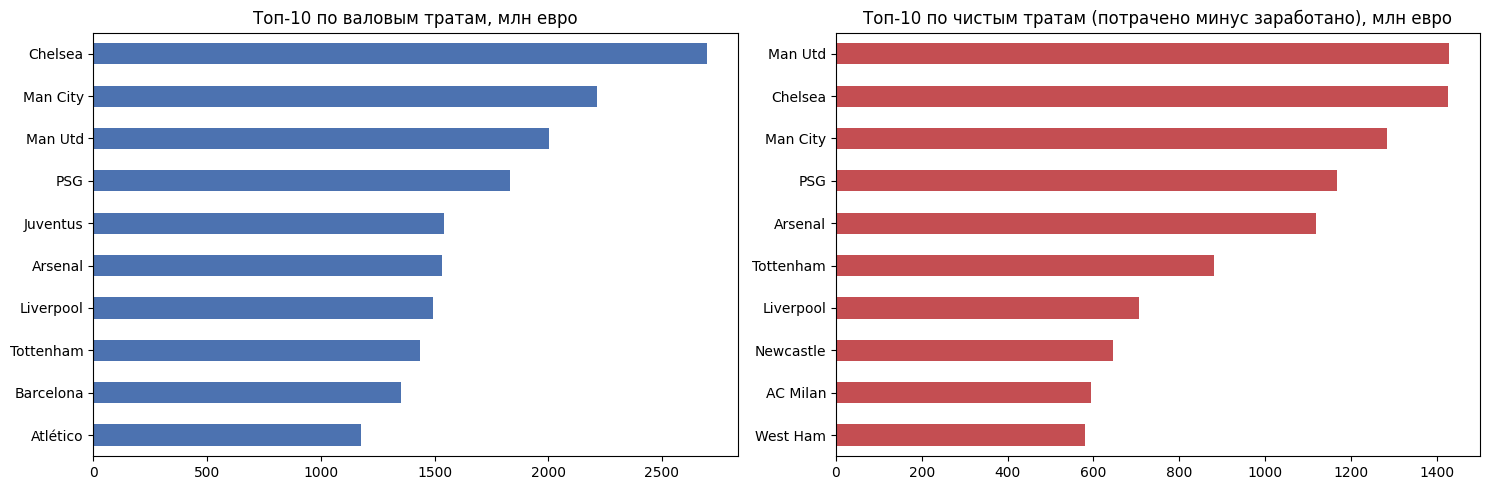

In [21]:
top5_ids = set(top5_clubs["club_id"])
spent = df.groupby("club_id")["fee_m"].sum()

# продажи: все сделки, где продавец — клуб топ-5 лиг, независимо от покупателя.
# Берём df_temp (рынок до фильтра «покупатель из топ-5»): в df остались только покупки клубов топ-5,
# и продажи в клубы вне топ-5 лиг были бы потеряны
sales = df_temp[df_temp["from_club_id"].isin(top5_ids)]
earned = sales.groupby("from_club_id")["transfer_fee"].sum() / 1_000_000

net = pd.DataFrame({"Потрачено": spent, "Заработано": earned}).fillna(0)
net["Net_Spend"] = net["Потрачено"] - net["Заработано"]
net["Club"] = club_names.reindex(net.index)
net = net.dropna(subset=["Club"]).set_index("Club").join(rfm["Segment"])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# два независимых топ-10: по валовым тратам и по чистым тратам — состав клубов может отличаться
net.nlargest(10, "Потрачено")["Потрачено"].sort_values().plot.barh(ax=axes[0], color="#4c72b0")
axes[0].set_title("Топ-10 по валовым тратам, млн евро")
axes[0].set_ylabel("")

net.nlargest(10, "Net_Spend")["Net_Spend"].sort_values().plot.barh(ax=axes[1], color="#c44e52")
axes[1].set_title("Топ-10 по чистым тратам (потрачено минус заработано), млн евро")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

# 8. Стиль торговли: покупатель или трейдер

Сегменты из раздела 6 построены только на покупках и не видят разницы между клубом, который тратит без оглядки на продажи, и клубом, который финансирует покупки продажей игроков (например, ставка на молодёжь с последующей перепродажей). Чтобы увидеть эту разницу, вводится дополнительный признак, независимый от сегментов:

```
Net_Trade_Ratio = (Потрачено − Заработано) / (Потрачено + Заработано)
```

Значение лежит в диапазоне [-1, 1]: около `+1` — клуб почти не продаёт, около `0` — покупки и продажи сбалансированы, отрицательные значения — продаж больше, чем покупок. «Заработано» — деньги от продажи игроков клубом топ-5 лиг любому покупателю, в том числе вне топ-5.

Клубы делятся на три равные по размеру группы (терцили) по этому показателю: границы берутся из данных, а не подбираются на глаз (так же, как медиана для среднего чека). Терцили относительные, поэтому «Скорее продавец» означает «нижняя треть выборки по Net_Trade_Ratio», а не обязательно отрицательное сальдо — фактические границы групп показаны в таблице ниже.

Это отдельный признак, а не замена сегментам: у «Точечных транжиров» тоже может быть любой стиль торговли, и наоборот.

In [22]:
denom = net["Потрачено"] + net["Заработано"]
net["Net_Trade_Ratio"] = np.where(denom > 0, (net["Потрачено"] - net["Заработано"]) / denom, np.nan)

STYLE_LABELS = ["Скорее продавец", "Сбалансированный", "Скорее покупатель"]
NO_DATA_LABEL = "Нет платных сделок"
has_ratio = net["Net_Trade_Ratio"].notna()

net["Trading_Style"] = NO_DATA_LABEL   # клубы без платных сделок: Потрачено = Заработано = 0
net.loc[has_ratio, "Trading_Style"] = pd.qcut(
    net.loc[has_ratio, "Net_Trade_Ratio"].rank(method="first"), 3, labels=STYLE_LABELS
).astype(str)

STYLE_ORDER = STYLE_LABELS + [NO_DATA_LABEL]
net["Trading_Style"] = pd.Categorical(net["Trading_Style"], categories=STYLE_ORDER, ordered=True)

print(f"Клубов без платных сделок: {(~has_ratio).sum()} из {len(net)}")
display(net["Trading_Style"].value_counts().reindex(STYLE_ORDER))

# фактические границы групп по Net_Trade_Ratio
display(net.groupby("Trading_Style", observed=True)["Net_Trade_Ratio"].agg(["min", "max", "count"]).round(2))

Клубов без платных сделок: 1 из 176


,count
Trading_Style,
Скорее продавец,58
Сбалансированный,58
Скорее покупатель,59
Нет платных сделок,1


,min,max,count
Trading_Style,,,
Скорее продавец,-1.00,-0.28,58
Сбалансированный,-0.27,0.05,58
Скорее покупатель,0.05,0.89,59
Нет платных сделок,NaN,NaN,0


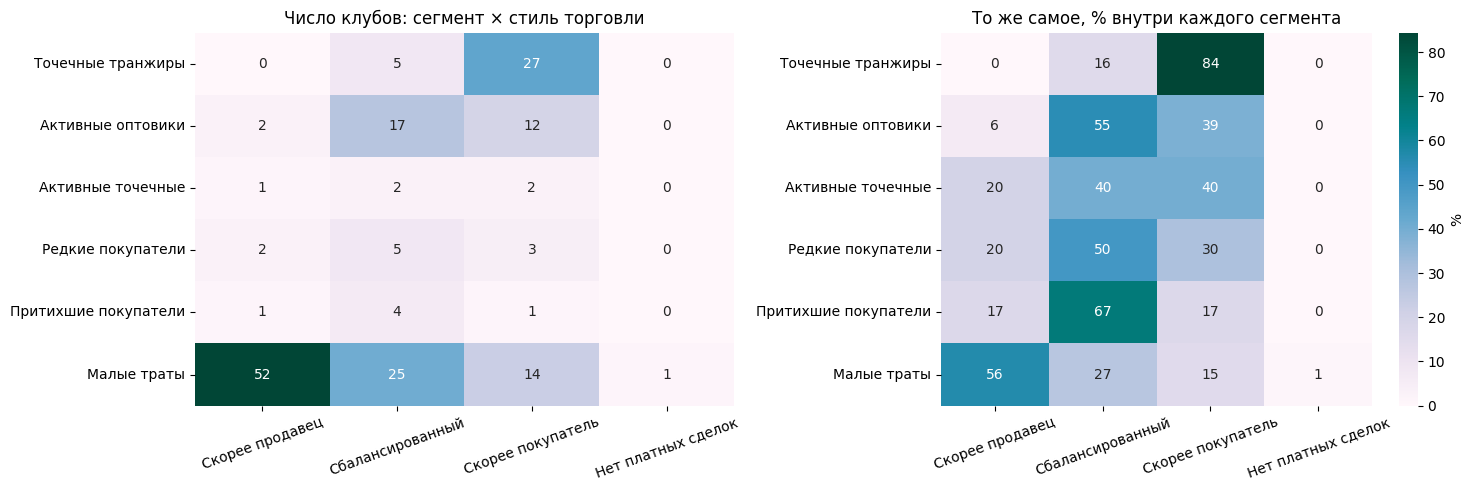

Trading_Style,Скорее продавец,Сбалансированный,Скорее покупатель,Нет платных сделок
Segment,,,,
Точечные транжиры,0,5,27,0
Активные оптовики,2,17,12,0
Активные точечные,1,2,2,0
Редкие покупатели,2,5,3,0
Притихшие покупатели,1,4,1,0
Малые траты,52,25,14,1


In [23]:
style_seg = pd.crosstab(net["Segment"], net["Trading_Style"]).reindex(columns=STYLE_ORDER, fill_value=0)
style_seg_pct = style_seg.div(style_seg.sum(axis=1), axis=0).mul(100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(style_seg, annot=True, fmt="d", cmap="PuBuGn", cbar=False, ax=axes[0])
axes[0].set_title("Число клубов: сегмент × стиль торговли")
axes[0].set_xlabel("")
axes[0].set_ylabel("")
axes[0].tick_params(axis="x", rotation=20)

sns.heatmap(style_seg_pct, annot=True, fmt=".0f", cmap="PuBuGn", cbar_kws={"label": "%"}, ax=axes[1])
axes[1].set_title("То же самое, % внутри каждого сегмента")
axes[1].set_xlabel("")
axes[1].set_ylabel("")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

display(style_seg)

In [24]:
# список клубов по сегментам и стилю торговли
# (net не перезаписываем: ниже он нужен с индексом по названию клуба)
clubs_by_group = net.reset_index().groupby(["Segment", "Trading_Style"], observed=True)["Club"].unique()

# показывать колонки без ограничения ширины
with pd.option_context('display.max_colwidth', None):
    print(clubs_by_group)

Segment               Trading_Style     
Точечные транжиры     Сбалансированный                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                       [Leverkusen, Dortmund, Monaco, Southampton, Stade Rennais]
                      Скорее покупатель                                                                                                                                                                                                                                                                

# 9. Ключевые выводы

Ячейка ниже собирает главные цифры автоматически, поэтому они всегда соответствуют текущим данным. Итоговое заключение — после неё.

In [25]:
elite = rfm[rfm["Segment"] == "Точечные транжиры"]
total_spend = rfm["Monetary"].sum()
top10_n = max(1, int(round(len(rfm) * 0.10)))
top10_share = rfm.nlargest(top10_n, "Monetary")["Monetary"].sum() / total_spend
top4 = rfm.nlargest(4, "Monetary")["Monetary"]
lead_league = rfm.groupby("League")["Monetary"].sum().idxmax()
lead_league_share = rfm.groupby("League")["Monetary"].sum().max() / total_spend
wholesalers = rfm.index[rfm["Segment"] == "Активные оптовики"].tolist()
fading = rfm.index[rfm["Segment"] == "Притихшие покупатели"].tolist()
biggest_net = net["Net_Spend"].idxmax()
biggest_seller = net["Net_Spend"].idxmin()
top3F = rfm.nlargest(3, "Frequency")["Frequency"]

print(f"Период: сезоны 2015/16 – {SNAPSHOT_SEASON}/{(SNAPSHOT_SEASON + 1) % 100:02d} | клубов: {len(rfm)} | суммарные траты: {total_spend:,.0f} млн евро")
print(f"1. Концентрация: топ-10% клубов ({top10_n} шт.) потратили {top10_share:.0%} всех денег.")
print(f"2. Точечные транжиры (элитный сегмент): {len(elite)} клубов ({len(elite) / len(rfm):.0%}), на них приходится {elite['Monetary'].sum() / total_spend:.0%} трат.")
print(f"3. Лидеры по суммарным тратам: " + ", ".join(f"{c} ({v:,.0f} млн)" for c, v in top4.items()))
print(f"4. Лига-лидер по расходам: {lead_league} ({lead_league_share:.0%} всех трат).")
print(f"5. Активные оптовики ({len(wholesalers)}): {', '.join(wholesalers[:8]) or '—'}")
print(f"6. Притихшие покупатели ({len(fading)}): {', '.join(fading[:8]) or '—'}")
print(f"7. Крупнейший чистый покупатель: {biggest_net} ({net.loc[biggest_net, 'Net_Spend']:,.0f} млн); крупнейший по чистому доходу от продаж: {biggest_seller} ({net.loc[biggest_seller, 'Net_Spend']:,.0f} млн).")
print(f"8. Больше всего сделок: " + ", ".join(f"{c} ({v})" for c, v in top3F.items()))

Период: сезоны 2015/16 – 2025/26 | клубов: 176 | суммарные траты: 54,950 млн евро
1. Концентрация: топ-10% клубов (18 шт.) потратили 47% всех денег.
2. Точечные транжиры (элитный сегмент): 32 клубов (18%), на них приходится 64% трат.
3. Лидеры по суммарным тратам: Chelsea (2,697 млн), Man City (2,216 млн), Man Utd (2,004 млн), PSG (1,834 млн)
4. Лига-лидер по расходам: Premier League (44% всех трат).
5. Активные оптовики (31): Frankfurt, Stuttgart, Wolfsburg, Real Betis, Augsburg, Marseille, Genoa, Sunderland
6. Притихшие покупатели (6): 1.FC Köln, FC Schalke 04, Hamburg, Stoke City, Middlesbrough, Swansea
7. Крупнейший чистый покупатель: Man Utd (1,429 млн); крупнейший по чистому доходу от продаж: Lille (-406 млн).
8. Больше всего сделок: Genoa (159), Hellas Verona (155), Roma (128)


## Заключение по результатам RFM-анализа трансферного рынка (сезоны 2015/16 – 2025/26)

**Объём исследования.** Проанализированы покупки 176 клубов топ-5 лиг за 11 сезонов; суммарные расходы на трансферы — около 55 млрд евро. Классический RFM (Recency — давность последней крупной сделки, Frequency — частота покупок, Monetary — общий объём трат) дополнен средним чеком, а соотношение продаж и покупок (Net Trade Ratio) введено отдельным признаком. Это позволило сегментировать клубы по их поведению на рынке.

**Ключевые выводы**

1. **Сильная концентрация расходов.** Топ-10% клубов (18 из 176) потратили 47% всех денег. Сегмент «Точечные транжиры» — 32 клуба (18% выборки) — даёт 64% всех трат. Это близко к принципу Парето, но мягче классического «80/20»: рынок сосредоточен у узкой группы клубов.

2. **Лидерство АПЛ.** На клубы Премьер-лиги пришлось 44% расходов всех клубов топ-5 лиг в выборке (около 24 млрд из 55).

3. **Лидеры по тратам.** По суммарным расходам впереди Chelsea (2 697 млн евро) и Man City (2 216 млн), затем Man Utd (2 004 млн) и PSG (1 834 млн). Крупнейшие чистые покупатели и клубы с наибольшим доходом от продаж определяются по Net_Spend (потрачено минус заработано): см. графики в разделе 7 и пункт 7 автоматического вывода выше.

4. **Разные способы тратить деньги.** При сопоставимых активности и масштабе клубы различаются по среднему чеку: «Точечные транжиры» покупают меньше игроков за большие суммы, «Активные оптовики» (31 клуб, например Frankfurt, Stuttgart, Marseille, Real Betis) — много недорогих игроков. Рекордная частота сделок у Genoa (159) и Hellas Verona (155), но Frequency включает аренды и свободных агентов с нулевой суммой: высокая частота сама по себе не означает больших денег — Verona, например, не вошла ни в один из активных сегментов.

5. **Притихшие покупатели** (6 клубов: FC Schalke 04, 1.FC Köln, Hamburg, Stoke City, Middlesbrough, Swansea) последний раз делали крупную покупку 8–10 сезонов назад. Все они в разные годы вылетали из высших лиг, поэтому паузу в крупных покупках естественно связывать со спортивным спадом — но это наблюдение, а не доказанная причинность.

6. **Малые траты — более половины клубов** (92 из 176, 52%), на них приходится лишь около 7% всех расходов. Это клубы без единой крупной сделки за 11 сезонов: «лифты» (Luton), экономные клубы Бундеслиги (Mainz, Freiburg), бывшие гранды Франции (Bordeaux).

7. **Серия A** — вторая по объёму расходов лига выборки после АПЛ; гипотезы о причинах (концентрация трат, циркуляция денег внутри лиги, налоговые льготы) и их проверка — в разделе 7.2.

**Ограничения**

- Суммы номинальные (без поправки на рост цен рынка): «крупная» сделка определяется внутри сезона, поэтому Recency от инфляции не зависит, а Monetary — зависит: поздние сезоны вносят больший вклад.
- В выборку входят клубы, у которых в таблице `clubs` указана одна из топ-5 лиг, включая клубы, позже вылетевшие из них.
- «Заработано» — деньги от продажи игроков клубами топ-5 лиг любому покупателю; сделки без суммы и аренды считаются нулём.
- Правило возврата из аренды — эвристика (зеркальная сделка того же игрока за 0 в пределах 730 дней).
- Более чем у половины клубов Recency = 11 (нет крупных сделок), поэтому на практике она разделяет клубы на «были крупные сделки» и «не было»; Recency и Monetary связаны (ρ Спирмена около −0,88), отчасти механически: Monetary — накопленная сумма за окно, а клуб, давно переставший покупать, просто не успел её накопить.